In [1]:
# 读入数据
import numpy as np
import pandas as pd
import os
import seaborn as sns
from xgboost import XGBRegressor
from scipy.stats import skew
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import PowerTransformer
from sklearn.linear_model import Lasso
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import make_pipeline

train_data = pd.read_csv("train.csv")
test_data = pd.read_csv("test.csv")

print(train_data.head())
print(train_data.shape)
print(test_data.shape)

   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  SalePrice  
0   2008        WD   

<Axes: xlabel='SalePrice', ylabel='Count'>

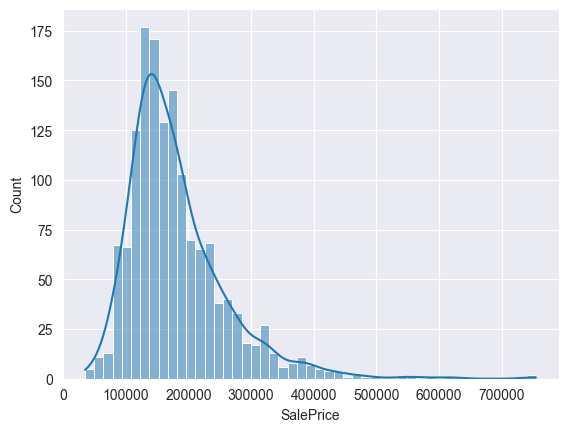

In [2]:
# 绘制房价直方图
sns.histplot(train_data['SalePrice'], kde=True)

In [3]:
# 数字特征相关性
corr_matrix = train_data.corr(numeric_only=True) # 相关性矩阵
corr_price = corr_matrix["SalePrice"].sort_values(ascending = False) # 与房价相关性列，按降序排列
print(corr_price.iloc[:15]) # 前十个特征及其相关性

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
Name: SalePrice, dtype: float64


<Axes: xlabel='OverallQual', ylabel='SalePrice'>

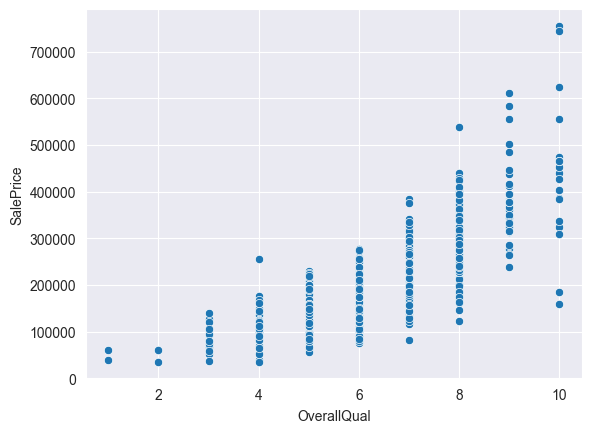

In [4]:
# 绘制材质及装修品质与房价散点图
sns.scatterplot(x="OverallQual", y="SalePrice", data=train_data)

In [5]:
# 有两个品质10级但价格小于200000的点
print(train_data[(train_data["OverallQual"] == 10) & (train_data["SalePrice"] <= 200000)][["OverallQual", "GrLivArea", "SalePrice"]])
# 经过检查这两个点地上面积大于4000，几乎不可能低价，无参考价值
# 异常值删掉
train_data = train_data.drop(train_data[(train_data["OverallQual"] == 10) & (train_data["SalePrice"] <= 200000)].index)

      OverallQual  GrLivArea  SalePrice
523            10       4676     184750
1298           10       5642     160000


<Axes: xlabel='GrLivArea', ylabel='SalePrice'>

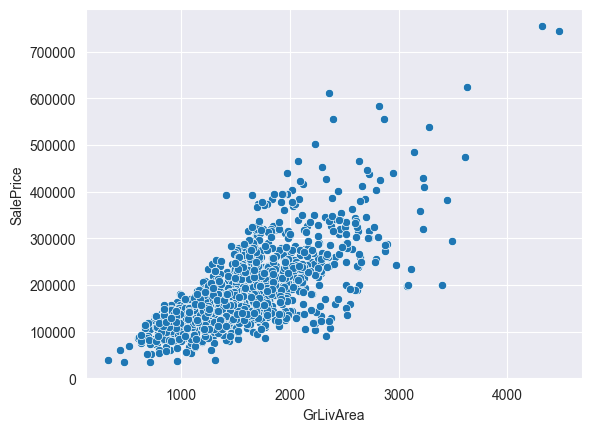

In [6]:
# 绘制地上面积与房价散点图
sns.scatterplot(x="GrLivArea", y="SalePrice", data=train_data)

In [7]:
# 扫描缺失值情况
missing_data = train_data.isnull().sum()
print(missing_data[missing_data > 0])

LotFrontage      259
Alley           1367
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1452
Fence           1177
MiscFeature     1404
dtype: int64


In [8]:
# 处理缺失值函数
def fill_missing(df):
    df = df.copy()
    # 第一类：需要填充None的字符串
    none_cols = [
        'Alley', 'MasVnrType', 'BsmtQual', 'BsmtCond', 'BsmtExposure',
        'BsmtFinType1', 'BsmtFinType2', 'FireplaceQu',
        'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
        'PoolQC', 'Fence', 'MiscFeature'
    ]
    df[none_cols] = df[none_cols].fillna("None")
    # 第二类：需要填充0的数值
    zero_cols =[
        'GarageYrBlt', 'GarageArea', 'GarageCars', 
        'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF','TotalBsmtSF', 
        'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea'
    ]
    df[zero_cols] = df[zero_cols].fillna(0)
    # 第三类：需要填充中位数的数值
    df["LotFrontage"] = df["LotFrontage"].fillna(df["LotFrontage"].median())
    # 第四类：需要填充众数的特征
    mode_cols =[
        'Electrical', 'MSZoning', 'Exterior1st', 'Exterior2nd',
        'SaleType', "Utilities", "KitchenQual", "Functional"
    ]
    for col in mode_cols:
        df[col] = df[col].fillna(df[col].mode()[0])
    return df

train_data = fill_missing(train_data)
missing_data = train_data.isnull().sum().sum()
print(f"清洗后训练数据缺失值数量：{missing_data}")
test_data = fill_missing(test_data)
missing_data = test_data.isnull().sum().sum()
print(f"清洗后测试数据缺失值数量：{missing_data}")

清洗后训练数据缺失值数量：0
清洗后测试数据缺失值数量：0


In [9]:
# 特征工程

# 提取目标变量进行对数转换
y_train = np.log1p(train_data['SalePrice'])

# 提取目标特征
X_train = train_data.drop(["Id", "SalePrice"], axis = 1)
X_test = test_data.drop(["Id"], axis = 1)
ntrain = X_train.shape[0]

# 合并训练集与测试集
all_data = pd.concat([X_train, X_test], axis = 0, ignore_index = True)

# Yeo-Johnson变换
numeric_feats = all_data.dtypes[all_data.dtypes != "object"].index
skewed_feats = all_data[numeric_feats].apply(skew).sort_values(ascending = False)
skewness = pd.DataFrame({'Skew':skewed_feats})
skewness = skewness[abs(skewness['Skew']) > 0.5]
skewed_features = skewness.index
print(f"{len(skewed_features)}个数值特征有拖尾...")
pt = PowerTransformer(method='yeo-johnson', standardize=True)
all_data[skewed_features] = pt.fit_transform(all_data[skewed_features])
print(f"已完成变换...")

# 独热编码
all_data = pd.get_dummies(all_data)

# 拆分训练集与测试集
X_train = all_data.iloc[:ntrain, :]
X_test = all_data.iloc[ntrain:, :]
print(f"最终 X_train 形状 (进模型前): {X_train.shape}")
print(f"最终 y_train 形状 (进模型前): {y_train.shape}")
print(f"最终 X_test 形状 (进模型前): {X_test.shape}")

28个数值特征有拖尾...
已完成变换...
最终 X_train 形状 (进模型前): (1458, 301)
最终 y_train 形状 (进模型前): (1458,)
最终 X_test 形状 (进模型前): (1459, 301)


In [10]:
# 模型
model_xgb= XGBRegressor(
    n_estimators=1500,    # 核心：决策树的数量
    learning_rate=0.01,   # 核心：学习率（步长）
    max_depth=4,          # 核心：单棵决策树的最大深度
    subsample=0.8,        # 防过拟合：训练每棵树时抽样的样本比例
    colsample_bytree=0.3, # 防过拟合：训练每棵树时抽样的特征比例
    min_child_weight=2,   # 防过拟合：叶子节点的最小样本权重和
    random_state=42       # 通用：固定随机种子，保证结果可复现
)

model_lasso = make_pipeline(
    RobustScaler(),  # 数据预处理：鲁棒标准化
    Lasso(
        alpha=0.0005,  # 核心：正则化强度
        random_state=42 # 通用：固定随机种子
    )
)

In [11]:
# 5折交叉验证
print("===5折交叉验证===")
score = - cross_val_score(model_xgb, X_train, y_train, cv = 5, scoring = "neg_root_mean_squared_error")
print(f"XGB5折交叉验证RMSE：{score.mean():.4f}")
score = -cross_val_score(model_lasso, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error')
print(f"Lasso5折交叉验证RMSE：{score.mean():.4f}")

===5折交叉验证===
XGB5折交叉验证RMSE：0.1131
Lasso5折交叉验证RMSE：0.1098


In [12]:
print("\n===正式训练===")
model_xgb.fit(X_train, y_train)
print("XGB训练完成...")
model_lasso.fit(X_train, y_train)
print("Lasso训练完成...")
predictions_xgb = model_xgb.predict(X_test)
predictions_lasso = model_lasso.predict(X_test)
y_test = np.expm1(predictions_xgb * 0.4 + predictions_lasso * 0.6)
print("预测完成...")


===正式训练===
XGB训练完成...
Lasso训练完成...
预测完成...


In [13]:
# 生成输出文件
print("\n===生成输出文件===")
output = pd.DataFrame({'Id': test_data.Id, 'SalePrice': y_test})
output.to_csv('house_price_submission.csv', index=False)
print("生成成功...")


===生成输出文件===
生成成功...
